# Titanic: calidad de los datos y patrones iniciales de supervivencia
## Sumativa 1 · Avance del proyecto, Fase 1 · Grupo 7
**Asignatura:** Exploración Inteligente para la Ciencia de Datos · Universidad Andrés Bello.

**Equipo de trabajo según el contexto disponible:** Felipe Palma Barrientos, Cristian Grandon Grandon y Jorge Gutierrez Jaramillo. Confirmar la nómina con el README antes de entregar.

**Dataset:** `titanic.csv`, versión del repositorio de ejemplos de seaborn.

**Propósito:** establecer una base reproducible que permita evaluar la calidad de los datos y describir cómo varía la supervivencia entre grupos de pasajeros.

**Base documental y alcance de esta versión:** se utilizó la rúbrica de Sumativa 1 facilitada y la estructura `F1/` de la imagen. El enlace del repositorio del Grupo 7 devolvió HTTP 404 en la revisión; por ello, la selección de Titanic sigue la recomendación de la rúbrica y no se presenta como una selección verificada en GitHub. No se dispuso de otros apuntes docentes ni de la planificación formativa. Su alineación con esos materiales queda pendiente.

### Índice
1. Identificación del proyecto (esta portada).
2. Contexto, objetivo y preguntas.
3. Carga y revisión inicial.
4. Exploración preliminar.
5. Decisiones, transformaciones y exportación.
6. Resultados e interpretación inicial.
7. Supuestos y limitaciones.
8. Cierre, reproducibilidad y referencias.

### Ejecución
Guardar este archivo en `F1/notebooks/`. Abrirlo en Jupyter o VS Code con Python 3.11 o posterior y ejecutar **Restart Kernel → Run All**. También se admite iniciar desde `F1/` o la raíz del proyecto. Si se abre desde otra ubicación, completar `RUTA_F1` en la primera celda de código.

Se necesitan `pandas`, `numpy`, `matplotlib` e `ipykernel`. Si faltan, ejecutar en una celda auxiliar `%pip install pandas numpy matplotlib ipykernel` y reiniciar el kernel. Las versiones efectivamente utilizadas se muestran y exportan al final.

La primera ejecución descarga el CSV desde internet; las siguientes reutilizan el archivo validando su SHA-256. No se utilizan tokens ni credenciales. `procesed` conserva la escritura solicitada por el usuario.

| Carpeta | Contenido |
|---|---|
| `F1/notebooks/` | Este notebook ejecutado |
| `F1/data/` | CSV original sin modificar |
| `F1/procesed/` | CSV transformado y esquema de sus variables |
| `F1/reports/` | Tablas, figuras, decisiones y registro de ejecución |

**Entrega académica:** la rúbrica también exige un PDF complementario de hasta 3 páginas; este notebook constituye el componente técnico y no sustituye ese documento.

## 2. Contexto, objetivo y preguntas exploratorias
El caso estudia registros de pasajeros del Titanic incluidos en una base de ejemplo. El problema exploratorio consiste en determinar qué patrones de supervivencia pueden describirse y qué restricciones de calidad condicionan su lectura. El valor de esta fase es orientar las comparaciones y decisiones de preparación de las etapas siguientes, sin atribuir causalidad a las diferencias observadas.

**Objetivo:** diagnosticar la estructura y calidad del dataset y describir la supervivencia según sexo registrado, clase del pasaje, edad y acompañamiento familiar, conservando una copia trazable de las transformaciones.

| Pregunta | Acción | Evidencia |
|---|---|---|
| P1. ¿Qué problemas de calidad presenta la base? | Revisar nulos, perfiles repetidos, dominios y redundancias | §3: diagnóstico y controles |
| P2. ¿Cómo se distribuyen edad, tarifa y supervivencia? | Estadísticos, histogramas y frecuencias | §4: descriptivos y figura 1 |
| P3. ¿Cómo varía la supervivencia según sexo y clase? | Tasas con denominadores, incluyendo cruce sexo–clase | §6.1: tablas y figura 2 |
| P4. ¿Qué diferencias aparecen según edad y acompañamiento? | Grupos de edad y tamaño familiar derivado | §5 y §6.2: tablas y figura 3 |

**Justificación del dataset:** Titanic está recomendado por la rúbrica y permite abordar variables numéricas, categorías, faltantes, redundancias y transformaciones en un primer ciclo de EDA.

**Alcance:** descripción de la base disponible; diagnóstico, transformaciones sencillas y comparaciones descriptivas. No se entrenan modelos ni se realizan pruebas causales. No se asume que los registros representen a todos los pasajeros o a la tripulación. Se emplean los casos observados por variable y se informan sus denominadores.

## 3. Carga y revisión inicial de datos
### 3.1. Preparación del entorno y organización de rutas
En la Fase 1, el Grupo 7 analiza la calidad de los registros del Titanic y describe la supervivencia según sexo registrado, clase, edad y acompañamiento familiar. Preparar un entorno común permite reproducir el análisis y relacionar los resultados con la fuente y las decisiones de transformación.

**Herramientas:** `pandas` permite cargar y resumir tablas; `numpy`, realizar operaciones numéricas y crear variables derivadas; y `matplotlib`, generar las visualizaciones. `pathlib` construye rutas compatibles con Windows y Linux. Las utilidades de descarga, hash y JSON se utilizan posteriormente para obtener la fuente, verificar su integridad y registrar las exportaciones.

| Ruta relativa al proyecto | Función en el análisis |
|---|---|
| `F1/data/` | Conservar el CSV original de Titanic, validado mediante SHA-256 en §3.2. |
| `F1/procesed/` | Guardar la tabla transformada y el esquema de variables de §5. Se conserva la escritura utilizada en este notebook. |
| `F1/reports/` | Reunir diagnósticos, tablas, figuras y decisiones que respaldan las respuestas a P1–P4. |

**Rutas reproducibles:** se busca la raíz del proyecto desde el directorio del kernel y sus carpetas superiores, identificándola por `README.md` y `F1/`. Esto permite trabajar desde la raíz, desde `F1/` —ubicación actual del notebook— o desde sus subcarpetas. Si el kernel se inicia fuera del repositorio, se debe configurar `RUTA_F1` con una carpeta existente. Si la ubicación no es válida, se detiene la ejecución para evitar crear resultados en una carpeta equivocada.

**Evidencia de preparación:** la celda muestra las rutas y las versiones utilizadas de Python y las bibliotecas principales; estas versiones se incorporan al registro de §8.2. Las opciones de presentación uniforman tablas y gráficos sin alterar los datos. La descarga y las transformaciones se realizan en los apartados siguientes.

In [ ]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Completar solo si el kernel se inicia fuera del proyecto.
RUTA_F1 = None  # Ejemplo en Windows: Path(r"C:\mi_proyecto\F1")
actual = Path.cwd().resolve()
if RUTA_F1 is not None:
    F1 = Path(RUTA_F1).expanduser().resolve()
    if F1.name != "F1" or not F1.is_dir():
        raise ValueError("RUTA_F1 debe apuntar a la carpeta F1 existente del proyecto.")
else:
    raiz_proyecto = next(
        (ruta for ruta in (actual, *actual.parents)
         if (ruta / "README.md").is_file() and (ruta / "F1").is_dir()),
        None,
    )
    if raiz_proyecto is None:
        raise FileNotFoundError(
            "No se encontró la raíz del proyecto (README.md y F1/). "
            "Inicia el kernel dentro del repositorio o configura RUTA_F1."
        )
    F1 = raiz_proyecto / "F1"

DATA = F1 / "data"
PROCESED = F1 / "procesed"
REPORTS = F1 / "reports"
for carpeta in (DATA, PROCESED, REPORTS):
    carpeta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})
versiones = {"python": platform.python_version(), "pandas": pd.__version__,
             "numpy": np.__version__, "matplotlib": matplotlib.__version__}
print("Directorio de trabajo del kernel:", actual)
print("Carpeta F1:", F1)
display(pd.DataFrame([
    {"Uso": "Datos originales", "Ruta": str(DATA)},
    {"Uso": "Datos transformados y esquema", "Ruta": str(PROCESED)},
    {"Uso": "Tablas, figuras y registros", "Ruta": str(REPORTS)},
]))
display(pd.Series(versiones, name="Versión ejecutada").to_frame())

Carpeta F1: C:\Users\emper\Exploraci-n-Inteligente-para-la-Ciencia-de-Datos.-Grupo-7\F1


,Versión ejecutada
python,3.14.8
pandas,3.1.1
numpy,2.5.5
matplotlib,3.11.2


### 3.2. Extracción: descargar el CSV en `data/`
Se utiliza una URL fijada a un commit del repositorio de datos de seaborn, en lugar de una rama que pueda cambiar. El hash controla que los bytes sean los de la versión revisada. Si el archivo local difiere, se detiene la ejecución y no se sobrescribe silenciosamente. La descarga se valida antes de guardarla. La función `read_csv` carga después esa copia local (pandas development team, s. f.).

In [2]:
COMMIT_DATOS = "a29a0141d20e156043ec257a64c8de3b3a03fd6e"
URL_CSV = f"https://raw.githubusercontent.com/mwaskom/seaborn-data/{COMMIT_DATOS}/titanic.csv"
SHA256_ESPERADO = "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2"
archivo_original = DATA / "titanic.csv"

if archivo_original.exists():
    contenido = archivo_original.read_bytes()
    modo_carga = "Copia local verificada"
else:
    try:
        with urlopen(URL_CSV, timeout=60) as respuesta:
            contenido = respuesta.read()
    except Exception as error:
        raise RuntimeError("No se pudo descargar el CSV. Revisa tu conexión y vuelve a ejecutar.") from error
    modo_carga = "Descarga desde la fuente fijada"

sha256_original = hashlib.sha256(contenido).hexdigest()
if sha256_original != SHA256_ESPERADO:
    raise ValueError("El CSV no coincide con la versión fijada. Revisa data/titanic.csv antes de continuar.")
if not archivo_original.exists():
    archivo_original.write_bytes(contenido)

df_original = pd.read_csv(archivo_original)
print(modo_carga)
print("Archivo:", archivo_original.relative_to(F1))
print("SHA-256:", sha256_original)
print(f"Dimensiones: {df_original.shape[0]} filas × {df_original.shape[1]} columnas")
display(df_original.head())
df_original.info()

Descarga desde la fuente fijada
Archivo: data\titanic.csv
SHA-256: 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2
Dimensiones: 891 filas × 15 columnas


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.28,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.92,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.10,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


### 3.3. Diccionario y diagnóstico de calidad — P1
Cada fila se trata como un registro de pasajero de la fuente, sin afirmar que sea una persona identificada inequívocamente. Esta versión no contiene `PassengerId`, nombre ni número de billete.

El diccionario distingue variables originales y derivadas presentes en la fuente. `survived` es el resultado: 1 indica supervivencia y 0 ausencia de supervivencia. La clase se interpreta como categoría ordinal, no como una magnitud continua.

In [3]:
descripciones = {
    "survived": "Supervivencia: 0 = no; 1 = sí",
    "pclass": "Clase del pasaje: 1, 2 o 3 (ordinal)",
    "sex": "Sexo registrado: female/male",
    "age": "Edad en años; puede contener fracciones y faltantes",
    "sibsp": "Número de hermanos/as y cónyuges a bordo",
    "parch": "Número de padres/madres e hijos/as a bordo",
    "fare": "Tarifa registrada; no se presume costo individual comparable",
    "embarked": "Puerto codificado: C, Q o S",
    "class": "Etiqueta de pclass: First, Second o Third",
    "who": "Categoría derivada: man, woman o child",
    "adult_male": "Indicador derivado de hombre adulto",
    "deck": "Cubierta registrada; no equivale a cabina completa",
    "embark_town": "Nombre del puerto de embarque",
    "alive": "Etiqueta de survived: yes/no",
    "alone": "Indicador de ausencia de familiares registrados",
}
diagnostico = pd.DataFrame({
    "variable": df_original.columns,
    "descripcion": [descripciones[x] for x in df_original.columns],
    "tipo_entrada": df_original.dtypes.astype(str).values,
    "nulos": df_original.isna().sum().values,
    "nulos_pct": df_original.isna().mean().mul(100).values,
    "valores_distintos": df_original.nunique(dropna=True).values,
})
repetidas = int(df_original.duplicated().sum())
display(diagnostico)
print(f"Filas idénticas adicionales a la primera: {repetidas}")
display(df_original.loc[df_original.duplicated(keep=False)].head(6))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True
26,0,3,male,NaN,0,0,7.22,C,Third,man,True,NaN,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.88,Q,Third,woman,False,NaN,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.90,S,Third,man,True,NaN,Southampton,no,True
32,1,3,female,NaN,0,0,7.75,Q,Third,woman,False,NaN,Queenstown,yes,True
37,0,3,male,21.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


In [4]:
controles = pd.Series({
    "Supervivencia completa y binaria": df_original["survived"].isin([0, 1]).all(),
    "Clase completa y válida": df_original["pclass"].isin([1, 2, 3]).all(),
    "Sexo completo y válido": df_original["sex"].isin(["female", "male"]).all(),
    "Edad observada entre 0 y 120": df_original["age"].dropna().between(0, 120).all(),
    "Tarifa completa y no negativa": df_original["fare"].notna().all() and df_original["fare"].ge(0).all(),
    "Conteos familiares completos, enteros y no negativos": (
        df_original[["sibsp", "parch"]].notna().all().all()
        and df_original[["sibsp", "parch"]].ge(0).all().all()
        and df_original[["sibsp", "parch"]].mod(1).eq(0).all().all()),
    "Puerto observado dentro del dominio": df_original["embarked"].dropna().isin(["C", "Q", "S"]).all(),
    "alive coincide con survived": df_original["alive"].eq(df_original["survived"].map({0: "no", 1: "yes"})).all(),
    "class coincide con pclass": df_original["class"].eq(df_original["pclass"].map({1: "First", 2: "Second", 3: "Third"})).all(),
    "alone coincide con sibsp + parch = 0": df_original["alone"].eq(df_original["sibsp"].add(df_original["parch"]).eq(0)).all(),
    "Puertos codificados y nombres coherentes": df_original["embarked"].map(
        {"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"}).fillna("Sin dato").eq(
        df_original["embark_town"].fillna("Sin dato")).all(),
}, name="Cumple")
display(controles.to_frame())
assert controles.all(), "Hay inconsistencias que deben revisarse antes de transformar."
display(Markdown(
    f"**Resultado P1:** `age` tiene {df_original.age.isna().sum()} faltantes "
    f"({df_original.age.isna().mean():.2%}); `deck`, {df_original.deck.isna().sum()} "
    f"({df_original.deck.isna().mean():.2%}); y `embarked`, {df_original.embarked.isna().sum()}. "
    f"Se observan {repetidas} filas idénticas adicionales. **Se conservan todas las filas**: "
    "sin un identificador de pasajero no se puede concluir que sean duplicaciones de carga. "
    "Las redundancias comprobadas se documentan para seleccionar las variables analíticas."
))

,Cumple
Supervivencia completa y binaria,True
Clase completa y válida,True
Sexo completo y válido,True
Edad observada entre 0 y 120,True
Tarifa completa y no negativa,True
"Conteos familiares completos, enteros y no negativos",True
Puerto observado dentro del dominio,True
alive coincide con survived,True
class coincide con pclass,True
alone coincide con sibsp + parch = 0,True


**Resultado P1:** `age` tiene 177 faltantes (19.87%); `deck`, 688 (77.22%); y `embarked`, 2. Se observan 107 filas idénticas adicionales. **Se conservan todas las filas**: sin un identificador de pasajero no se puede concluir que sean duplicaciones de carga. Las redundancias comprobadas se documentan para seleccionar las variables analíticas.

## 4. Exploración preliminar — P2
**Acción:** describir las variables numéricas con cantidad observada, cuartiles, mediana y extremos; mostrar frecuencias de categorías. La clase y supervivencia se resumen con frecuencias, aunque su almacenamiento sea numérico.

**Decisión:** no rellenar edades para describir su distribución. Se reporta la cantidad de observaciones utilizadas. Las tarifas altas se inspeccionan con la regla de 1,5 veces el rango intercuartílico; esa regla señala valores para revisión y no demuestra errores.

In [5]:
resumen_numerico = df_original[["age", "fare", "sibsp", "parch"]].describe().T
resumen_numerico["faltantes"] = df_original[["age", "fare", "sibsp", "parch"]].isna().sum()
display(resumen_numerico)
frecuencias = pd.concat([
    df_original[v].fillna("Sin dato").value_counts(dropna=False).rename_axis("categoria").reset_index(name="n").assign(variable=v)
    for v in ["survived", "sex", "pclass", "embarked"]
], ignore_index=True)
frecuencias["porcentaje"] = frecuencias["n"] / len(df_original) * 100
display(frecuencias[["variable", "categoria", "n", "porcentaje"]])
q1, q3 = df_original["fare"].quantile([0.25, 0.75])
limite_tarifa = q3 + 1.5 * (q3 - q1)
n_tarifas_altas = int(df_original["fare"].gt(limite_tarifa).sum())
print(f"Tarifas sobre Q3 + 1,5 × RIC ({limite_tarifa:.2f}): {n_tarifas_altas}. Se conservan.")

,variable,categoria,n,porcentaje
0,survived,0,549,61.62
1,survived,1,342,38.38
2,sex,male,577,64.76
3,sex,female,314,35.24
4,pclass,3,491,55.11
5,pclass,1,216,24.24
6,pclass,2,184,20.65
7,embarked,S,644,72.28
8,embarked,C,168,18.86
9,embarked,Q,77,8.64


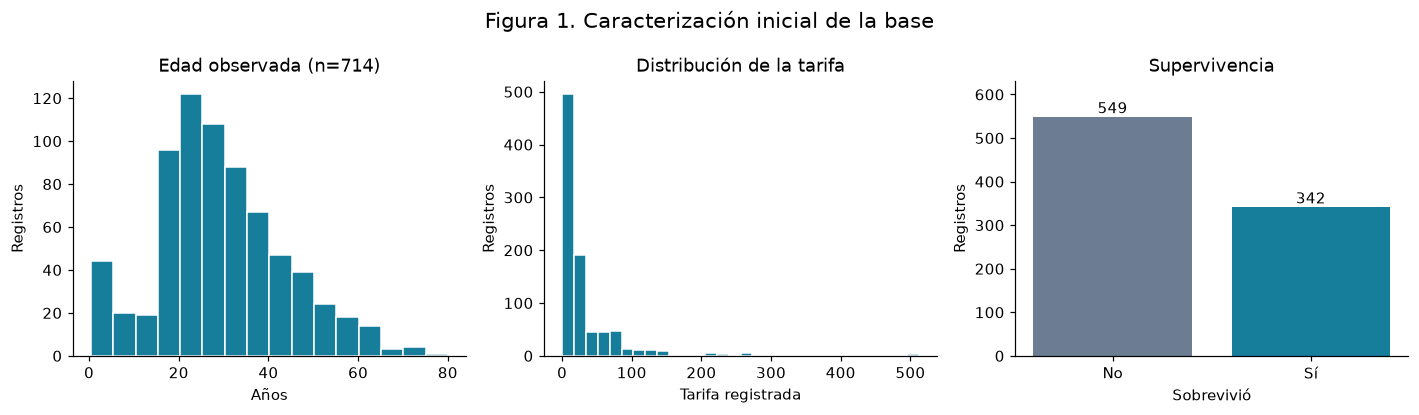

**Resultado P2:** la supervivencia global es 38.38% (342 de 891 registros). La edad mediana observada es 28.0 años y se calcula sobre 714 edades. La tarifa presenta una cola hacia valores altos: su media es 32.20 y su mediana 14.45. La mediana complementa la media para describir esta asimetría; no se recortan extremos.

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(df_original["age"].dropna(), bins=16, color="#167d9a", edgecolor="white")
axes[0].set(title=f"Edad observada (n={df_original.age.notna().sum()})", xlabel="Años", ylabel="Registros")
axes[1].hist(df_original["fare"], bins=30, color="#167d9a", edgecolor="white")
axes[1].set(title="Distribución de la tarifa", xlabel="Tarifa registrada", ylabel="Registros")
conteos_supervivencia = df_original["survived"].value_counts().reindex([0, 1])
axes[2].bar(["No", "Sí"], conteos_supervivencia, color=["#6b7c93", "#167d9a"])
axes[2].set(title="Supervivencia", xlabel="Sobrevivió", ylabel="Registros")
for i, valor in enumerate(conteos_supervivencia):
    axes[2].text(i, valor + 8, str(valor), ha="center")
axes[2].set_ylim(0, conteos_supervivencia.max() * 1.15)
fig.suptitle("Figura 1. Caracterización inicial de la base", fontsize=14)
fig.tight_layout()
fig.savefig(REPORTS / "figura_01_distribuciones.png", dpi=160, bbox_inches="tight")
plt.show()
display(Markdown(
    f"**Resultado P2:** la supervivencia global es {df_original.survived.mean():.2%} "
    f"({df_original.survived.sum()} de {len(df_original)} registros). "
    f"La edad mediana observada es {df_original.age.median():.1f} años y se calcula sobre "
    f"{df_original.age.notna().sum()} edades. La tarifa presenta una cola hacia valores altos: "
    f"su media es {df_original.fare.mean():.2f} y su mediana {df_original.fare.median():.2f}. "
    "La mediana complementa la media para describir esta asimetría; no se recortan extremos."
))

## 5. Decisiones y transformaciones iniciales
### 5.1. Transformar sin perder la fuente
El ETL sigue la secuencia **descargar → diagnosticar → transformar una copia → validar → exportar**.

| Decisión | Justificación | Efecto esperado |
|---|---|---|
| Conservar las filas, incluidas las repetidas | No hay un identificador para validar duplicados de personas | No alterar los denominadores |
| Mantener las edades ausentes | Evitar introducir edades artificiales en el EDA | Análisis numérico con casos observados |
| Excluir `deck` de la tabla analítica | Alta ausencia y sin pregunta específica de cubierta | Fuente íntegra disponible en `data/` |
| Seleccionar variables sin etiquetas redundantes | `alive`, `class`, `alone` duplican información; `who` y `adult_male` son derivadas | Tabla analítica más clara |
| Crear `tamano_familiar` y `acompanamiento` | Responder P4 a partir de `sibsp` y `parch` | Medida de familiares registrados, no de grupos reales |
| Crear `grupo_edad` | Comparar edades con cortes explícitos | Menor de 18; 18 a <60; 60 o más; sin dato |
| Añadir `id_fila_origen` | Vincular cada registro a la fila de esta versión | Identificador técnico, no PassengerId |

Los cortes etarios son una convención exploratoria del equipo. No se afirma que reproduzcan una política histórica. La etiqueta «sin dato» se aplica al grupo de edad y al puerto, pero no reemplaza el valor numérico de edad (pandas development team, s. f.).

In [7]:
columnas_base = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
df = df_original[columnas_base].copy()
df.insert(0, "id_fila_origen", np.arange(1, len(df) + 1))
df["pclass"] = pd.Categorical(df["pclass"], categories=[1, 2, 3], ordered=True)
df["sex"] = df["sex"].astype("category")
df["embarked"] = df["embarked"].fillna("Sin dato").astype("category")
df["tamano_familiar"] = df["sibsp"] + df["parch"] + 1
df["acompanamiento"] = pd.Categorical(
    np.where(df["tamano_familiar"].eq(1), "Sin familiares registrados", "Con familiares registrados"),
    categories=["Sin familiares registrados", "Con familiares registrados"])
df["edad_faltante"] = df["age"].isna()
df["grupo_edad"] = pd.cut(df["age"], bins=[0, 18, 60, np.inf], right=False,
    labels=["Menor de 18", "18 a menos de 60", "60 o más"])
df["grupo_edad"] = df["grupo_edad"].cat.add_categories(["Sin dato"]).fillna("Sin dato")

assert len(df) == len(df_original), "La transformación cambió la cantidad de registros."
assert df["id_fila_origen"].is_unique
assert df["survived"].equals(df_original["survived"])
assert df["age"].equals(df_original["age"])
assert df["fare"].equals(df_original["fare"])
assert df["tamano_familiar"].ge(1).all()
assert df["grupo_edad"].eq("Sin dato").sum() == df_original["age"].isna().sum()
assert hashlib.sha256(archivo_original.read_bytes()).hexdigest() == SHA256_ESPERADO

display(df.head())
print(f"Resultado de transformación: {len(df)} filas × {df.shape[1]} columnas. No se eliminaron registros.")

### 5.2. Resultados intermedios y registro de decisiones
El registro siguiente conecta cada decisión con un resultado calculado durante la ejecución. No constituye una auditoría histórica: documenta este primer ciclo de EDA.

In [8]:
decisiones = pd.DataFrame([
    ["D1", "§3.2", "Fijar fuente y validar hash", "Reproducir los mismos bytes", f"{len(df_original)} filas; SHA-256 verificado"],
    ["D2", "§3.3 / §5.1", "Conservar perfiles repetidos", "No hay identificador de persona", f"{repetidas} repeticiones adicionales conservadas"],
    ["D3", "§4 / §5.1", "No imputar edad", "Describir observaciones disponibles", f"{df.age.notna().sum()} edades observadas; {df.age.isna().sum()} ausentes"],
    ["D4", "§5.1", "Seleccionar 8 variables originales", "Reducir redundancias y delimitar preguntas", f"{df_original.deck.isna().sum()} nulos de deck documentados; fuente preservada"],
    ["D5", "§5.1", "Etiquetar puerto ausente", "Conservar y visibilizar ausencia", f"{df.embarked.eq('Sin dato').sum()} registros sin puerto"],
    ["D6", "§5.1", "Derivar tamaño familiar y acompañamiento", "Responder P4", f"{df.tamano_familiar.eq(1).sum()} registros sin familiares"],
    ["D7", "§5.1", "Agrupar edad con cortes explícitos", "Comparación descriptiva", f"{df.grupo_edad.nunique()} grupos presentes, incluyendo ausencia"],
    ["D8", "§4", "Conservar tarifas extremas", "Regla RIC no demuestra errores", f"{n_tarifas_altas} tarifas sobre el umbral superior"],
], columns=["id", "seccion", "decision", "motivo", "resultado_intermedio"])
display(decisiones)
decisiones.to_csv(REPORTS / "decisiones_exploratorias.csv", index=False, encoding="utf-8-sig")
diagnostico.to_csv(REPORTS / "diagnostico_calidad.csv", index=False, encoding="utf-8-sig")
resumen_numerico.to_csv(REPORTS / "resumen_numerico.csv", encoding="utf-8-sig")
frecuencias.to_csv(REPORTS / "frecuencias.csv", index=False, encoding="utf-8-sig")

,id,seccion,decision,motivo,resultado_intermedio
0,D1,§3.2,Fijar fuente y validar hash,Reproducir los mismos bytes,891 filas; SHA-256 verificado
1,D2,§3.3 / §5.1,Conservar perfiles repetidos,No hay identificador de persona,107 repeticiones adicionales conservadas
2,D3,§4 / §5.1,No imputar edad,Describir observaciones disponibles,714 edades observadas; 177 ausentes
3,D4,§5.1,Seleccionar 8 variables originales,Reducir redundancias y delimitar preguntas,688 nulos de deck documentados; fuente preservada
4,D5,§5.1,Etiquetar puerto ausente,Conservar y visibilizar ausencia,2 registros sin puerto
5,D6,§5.1,Derivar tamaño familiar y acompañamiento,Responder P4,537 registros sin familiares
6,D7,§5.1,Agrupar edad con cortes explícitos,Comparación descriptiva,"4 grupos presentes, incluyendo ausencia"
7,D8,§4,Conservar tarifas extremas,Regla RIC no demuestra errores,116 tarifas sobre el umbral superior


### 5.3. Carga: exportar a `procesed/`
El CSV conserva columnas, valores y orden de filas, pero no almacena los tipos categóricos de pandas. Por eso se exporta también un esquema JSON que registra tipos, categorías y orden. Se comprueba la lectura del CSV guardado para verificar la coherencia entre la tabla de trabajo y el archivo producido. En una nueva ejecución se reemplazan los resultados derivados de esta misma versión.

In [9]:
archivo_procesado = PROCESED / "titanic_procesado.csv"
df.to_csv(archivo_procesado, index=False, encoding="utf-8-sig")
esquema = {}
for nombre in df.columns:
    serie = df[nombre]
    esquema[nombre] = {"dtype": str(serie.dtype)}
    if isinstance(serie.dtype, pd.CategoricalDtype):
        esquema[nombre]["categorias"] = serie.cat.categories.tolist()
        esquema[nombre]["ordenada"] = serie.cat.ordered
(PROCESED / "esquema_titanic_procesado.json").write_text(
    json.dumps(esquema, indent=2, ensure_ascii=False), encoding="utf-8")

verificacion = pd.read_csv(archivo_procesado)
for nombre in ["pclass", "sex", "embarked", "acompanamiento", "grupo_edad"]:
    verificacion[nombre] = pd.Categorical(verificacion[nombre],
        categories=df[nombre].cat.categories, ordered=df[nombre].cat.ordered)
pd.testing.assert_frame_equal(df, verificacion)
print("CSV exportado y validado:", archivo_procesado.relative_to(F1))

CSV exportado y validado: procesed\titanic_procesado.csv


## 6. Resultados e interpretación inicial
### 6.1. Supervivencia según sexo registrado y clase — P3
**Acción:** calcular registros, supervivientes y tasa por grupo; después cruzar sexo y clase para verificar si la comparación marginal se mantiene dentro de cada clase. La tasa es `supervivientes / registros × 100`. Los denominadores acompañan todas las comparaciones. Son porcentajes descriptivos, sin intervalos inferenciales ni pruebas de hipótesis.

,sex,registros,supervivientes,no_supervivientes,supervivencia_pct
0,female,314,233,81,74.20
1,male,577,109,468,18.89


,pclass,registros,supervivientes,no_supervivientes,supervivencia_pct
0,1,216,136,80,62.96
1,2,184,87,97,47.28
2,3,491,119,372,24.24


,pclass,sex,registros,supervivientes,no_supervivientes,supervivencia_pct
0,1,female,94,91,3,96.81
1,1,male,122,45,77,36.89
2,2,female,76,70,6,92.11
3,2,male,108,17,91,15.74
4,3,female,144,72,72,50.00
5,3,male,347,47,300,13.54


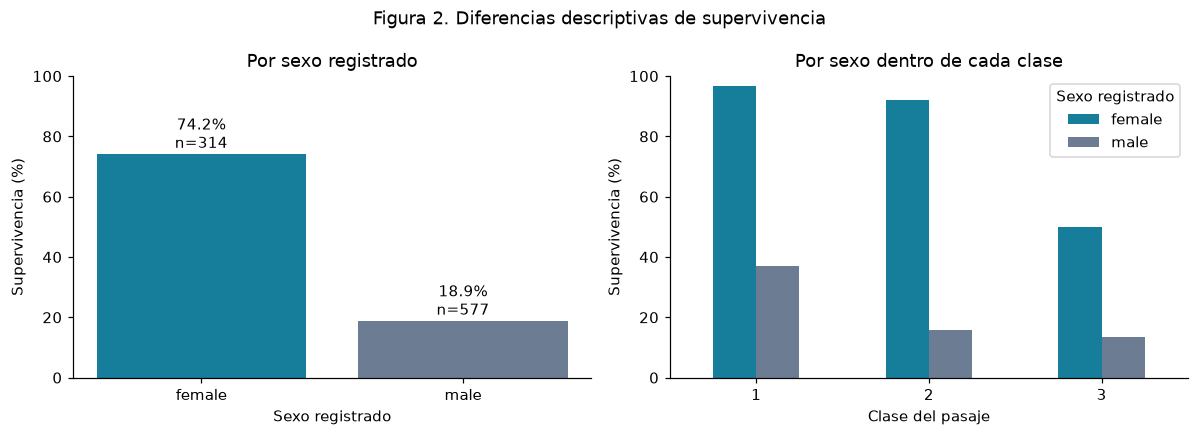

**Resultado P3:** la supervivencia es 74.20% en `female` y 18.89% en `male`, una diferencia de 55.31 puntos porcentuales. Por clase, las tasas son 62.96%, 47.28% y 24.24% para primera, segunda y tercera. El cruce muestra una supervivencia mayor de `female` dentro de las tres clases. La estratificación describe la composición de los registros, pero no controla todos los factores ni permite atribuir un efecto causal al sexo o a la clase.

In [10]:
def resumir_supervivencia(datos, grupos):
    tabla = datos.groupby(grupos, observed=True, dropna=False)["survived"].agg(
        registros="size", supervivientes="sum")
    tabla["no_supervivientes"] = tabla["registros"] - tabla["supervivientes"]
    tabla["supervivencia_pct"] = tabla["supervivientes"] / tabla["registros"] * 100
    return tabla.reset_index()

por_sexo = resumir_supervivencia(df, "sex")
por_clase = resumir_supervivencia(df, "pclass")
por_sexo_clase = resumir_supervivencia(df, ["pclass", "sex"])
display(por_sexo, por_clase, por_sexo_clase)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(por_sexo["sex"].astype(str), por_sexo["supervivencia_pct"], color=["#167d9a", "#6b7c93"])
axes[0].set(title="Por sexo registrado", xlabel="Sexo registrado", ylabel="Supervivencia (%)", ylim=(0, 100))
for i, fila in por_sexo.iterrows():
    axes[0].text(i, fila.supervivencia_pct + 2, f"{fila.supervivencia_pct:.1f}%\nn={fila.registros}", ha="center")
cruce = por_sexo_clase.pivot(index="pclass", columns="sex", values="supervivencia_pct")
cruce.plot.bar(ax=axes[1], color=["#167d9a", "#6b7c93"], rot=0)
axes[1].set(title="Por sexo dentro de cada clase", xlabel="Clase del pasaje", ylabel="Supervivencia (%)", ylim=(0, 100))
axes[1].legend(title="Sexo registrado")
fig.suptitle("Figura 2. Diferencias descriptivas de supervivencia")
fig.tight_layout()
fig.savefig(REPORTS / "figura_02_sexo_clase.png", dpi=160, bbox_inches="tight")
plt.show()
t_sexo = por_sexo.set_index("sex")["supervivencia_pct"]
t_clase = por_clase.set_index("pclass")["supervivencia_pct"]
display(Markdown(
    f"**Resultado P3:** la supervivencia es {t_sexo['female']:.2f}% en `female` y "
    f"{t_sexo['male']:.2f}% en `male`, una diferencia de {t_sexo['female'] - t_sexo['male']:.2f} "
    f"puntos porcentuales. Por clase, las tasas son {t_clase[1]:.2f}%, {t_clase[2]:.2f}% "
    f"y {t_clase[3]:.2f}% para primera, segunda y tercera. "
    "El cruce muestra una supervivencia mayor de `female` dentro de las tres clases. "
    "La estratificación describe la composición de los registros, pero no controla todos los factores "
    "ni permite atribuir un efecto causal al sexo o a la clase."
))

### 6.2. Edad y acompañamiento familiar — P4
Se mantiene «Sin dato» como grupo visible para no ocultar las edades ausentes. «Sin familiares registrados» significa `sibsp + parch = 0`; una persona podía viajar con amistades u otros acompañantes no cubiertos por esas columnas. La comparación marginal de acompañamiento puede reflejar diferencias de edad, sexo y clase.

,grupo_edad,registros,supervivientes,no_supervivientes,supervivencia_pct
0,Menor de 18,113,61,52,53.98
1,18 a menos de 60,575,222,353,38.61
2,60 o más,26,7,19,26.92
3,Sin dato,177,52,125,29.38


,acompanamiento,registros,supervivientes,no_supervivientes,supervivencia_pct
0,Sin familiares registrados,537,163,374,30.35
1,Con familiares registrados,354,179,175,50.56


,edad_faltante,registros,supervivientes,no_supervivientes,supervivencia_pct
0,False,714,290,424,40.62
1,True,177,52,125,29.38


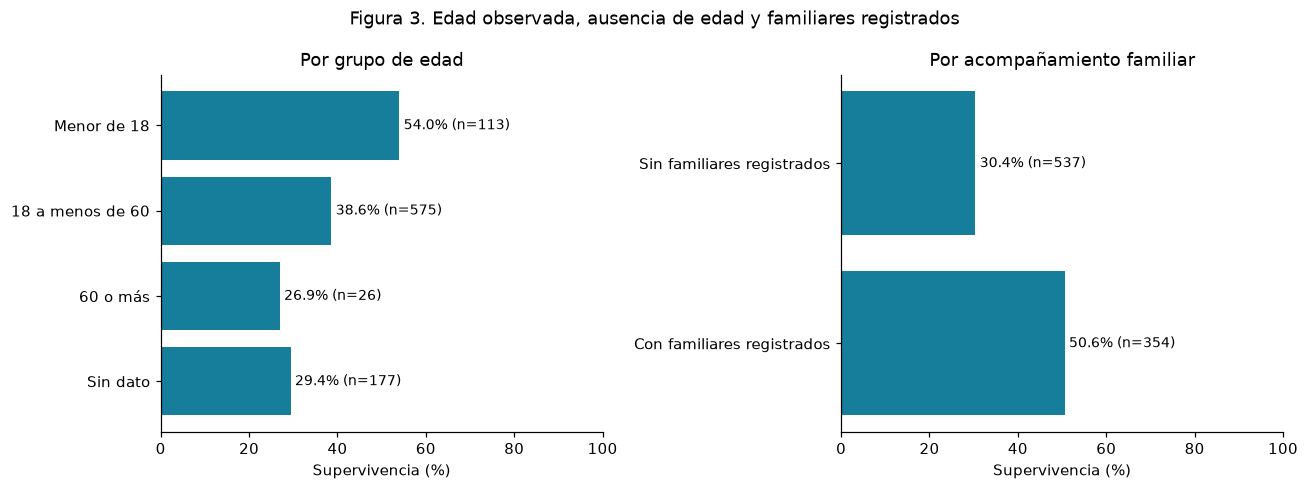

**Resultado P4:** la supervivencia alcanza 53.98% en menores de 18, 38.61% entre 18 y menos de 60, y 26.92% en edades de 60 o más. Con familiares registrados es 50.56% y sin ellos 30.35%. Los registros sin edad presentan 29.38% de supervivencia frente a 40.62% con edad observada. Esta diferencia aconseja evaluar la ausencia antes de una futura imputación; no demuestra por sí sola un mecanismo de datos faltantes. Los grupos etarios tienen tamaños distintos y la agrupación pierde detalle de la edad continua.

In [11]:
por_edad = resumir_supervivencia(df, "grupo_edad")
por_acompanamiento = resumir_supervivencia(df, "acompanamiento")
por_ausencia_edad = resumir_supervivencia(df, "edad_faltante")
display(por_edad, por_acompanamiento, por_ausencia_edad)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, tabla, variable, titulo in [
    (axes[0], por_edad, "grupo_edad", "Por grupo de edad"),
    (axes[1], por_acompanamiento, "acompanamiento", "Por acompañamiento familiar")]:
    ax.barh(tabla[variable].astype(str), tabla["supervivencia_pct"], color="#167d9a")
    ax.set(title=titulo, xlabel="Supervivencia (%)", xlim=(0, 100))
    ax.invert_yaxis()
    for i, fila in tabla.iterrows():
        ax.text(fila.supervivencia_pct + 1, i, f"{fila.supervivencia_pct:.1f}% (n={fila.registros})", va="center", fontsize=9)
fig.suptitle("Figura 3. Edad observada, ausencia de edad y familiares registrados")
fig.tight_layout()
fig.savefig(REPORTS / "figura_03_edad_acompanamiento.png", dpi=160, bbox_inches="tight")
plt.show()
t_edad = por_edad.set_index("grupo_edad")["supervivencia_pct"]
t_acomp = por_acompanamiento.set_index("acompanamiento")["supervivencia_pct"]
t_ausencia = por_ausencia_edad.set_index("edad_faltante")["supervivencia_pct"]
display(Markdown(
    f"**Resultado P4:** la supervivencia alcanza {t_edad['Menor de 18']:.2f}% en menores de 18, "
    f"{t_edad['18 a menos de 60']:.2f}% entre 18 y menos de 60, y {t_edad['60 o más']:.2f}% "
    f"en edades de 60 o más. Con familiares registrados es "
    f"{t_acomp['Con familiares registrados']:.2f}% y sin ellos "
    f"{t_acomp['Sin familiares registrados']:.2f}%. "
    f"Los registros sin edad presentan {t_ausencia[True]:.2f}% de supervivencia frente a "
    f"{t_ausencia[False]:.2f}% con edad observada. Esta diferencia aconseja evaluar la ausencia "
    "antes de una futura imputación; no demuestra por sí sola un mecanismo de datos faltantes. "
    "Los grupos etarios tienen tamaños distintos y la agrupación pierde detalle de la edad continua."
))

In [12]:
tablas_resultado = {
    "supervivencia_sexo": por_sexo,
    "supervivencia_clase": por_clase,
    "supervivencia_sexo_clase": por_sexo_clase,
    "supervivencia_edad": por_edad,
    "supervivencia_acompanamiento": por_acompanamiento,
    "supervivencia_ausencia_edad": por_ausencia_edad,
}
for nombre, tabla in tablas_resultado.items():
    assert tabla["registros"].sum() == len(df), f"Denominadores incoherentes: {nombre}"
    assert tabla["supervivientes"].sum() == df["survived"].sum()
    tabla.to_csv(REPORTS / f"{nombre}.csv", index=False, encoding="utf-8-sig")
print("Se exportaron seis tablas de resultados con denominadores verificados.")

Se exportaron seis tablas de resultados con denominadores verificados.


## 7. Supuestos, limitaciones y pendientes
| Aspecto | Supuesto o limitación | Consecuencia |
|---|---|---|
| Unidad de análisis | Cada fila representa un registro de la fuente; no hay ID personal | Los perfiles idénticos no se eliminan como personas duplicadas |
| Cobertura | Base de ejemplo, no un censo demostrado del naufragio | Hallazgos restringidos a los registros disponibles |
| Edad ausente | Se desconoce el mecanismo de ausencia | No se asume MCAR, MAR o MNAR; no se imputa en F1 |
| Cubierta | Alta proporción de faltantes | No sustenta una comparación principal en esta fase |
| Tarifa | Valores extremos y posible estructura compartida por billete | No equivale necesariamente a gasto individual ni ingreso |
| Familiares | `sibsp` y `parch` cubren relaciones específicas | Tamaño familiar no identifica familias ni todo acompañamiento |
| Categorías | `sex` usa las etiquetas de la fuente | No se infieren identidades más allá de esos datos |
| Comparaciones | Tasas marginales y cruce sexo–clase, sin ajuste completo | Asociación descriptiva; no causalidad ni predicción |
| Grupos etarios | Cortes definidos para esta exploración | Resultados dependen de la agrupación; revisar sensibilidad después |
| CSV | No preserva los tipos categóricos | Consultar el esquema JSON al reutilizar la tabla |
| Contexto docente | Solo se verificó la rúbrica adjunta | Contrastar preguntas, equipo y formato con el GitHub y la formativa |

**Continuidad propuesta:** validar el contexto del repositorio; profundizar la ausencia de edad según sexo y clase; evaluar sensibilidad a cortes etarios; revisar tarifas con información adicional si se incorpora otra fuente. Cualquier integración futura debe justificar llaves y cardinalidad. No se fabrica una unión de tablas ni se entrena un modelo para aumentar artificialmente el alcance de F1.

## 8. Cierre del avance y reproducibilidad
### 8.1. Síntesis vinculada con las preguntas
La siguiente tabla se calcula a partir de los resultados anteriores y sirve como base verificable para el PDF complementario. Sus cifras no están escritas manualmente.

In [13]:
hallazgos = pd.DataFrame([
    ["P1", "§3.3", f"{len(df_original)} registros; {df_original.age.isna().sum()} edades ausentes; {repetidas} repeticiones adicionales conservadas.", "Diagnóstico previo a cualquier imputación o eliminación."],
    ["P2", "§4", f"Supervivencia global: {df.survived.mean():.2%}. Mediana de edad: {df.age.median():.1f}. Mediana de tarifa: {df.fare.median():.2f}.", "Distribuciones descritas con denominadores y mediana."],
    ["P3", "§6.1", f"female: {t_sexo['female']:.2f}%; male: {t_sexo['male']:.2f}%. Clase 1: {t_clase[1]:.2f}%; clase 3: {t_clase[3]:.2f}%.", "Diferencias descriptivas que no prueban causalidad."],
    ["P4", "§6.2", f"Menores de 18: {t_edad['Menor de 18']:.2f}%. Con familiares: {t_acomp['Con familiares registrados']:.2f}%; sin familiares: {t_acomp['Sin familiares registrados']:.2f}%.", "Comparaciones sujetas a composición y ausencia de edad."],
], columns=["pregunta", "evidencia_notebook", "hallazgo", "interpretacion"])
display(hallazgos)
hallazgos.to_csv(REPORTS / "hallazgos_iniciales.csv", index=False, encoding="utf-8-sig")

,pregunta,evidencia_notebook,hallazgo,interpretacion
0,P1,§3.3,891 registros; 177 edades ausentes; 107 repeti...,Diagnóstico previo a cualquier imputación o el...
1,P2,§4,Supervivencia global: 38.38%. Mediana de edad:...,Distribuciones descritas con denominadores y m...
2,P3,§6.1,female: 74.20%; male: 18.89%. Clase 1: 62.96%;...,Diferencias descriptivas que no prueban causal...
3,P4,§6.2,Menores de 18: 53.98%. Con familiares: 50.56%;...,Comparaciones sujetas a composición y ausencia...


### 8.2. Evidencia de ejecución
Se registra la fuente, sus hashes, dimensiones y versiones del entorno. No hay muestreo aleatorio ni algoritmos estocásticos, por lo que no se necesita fijar una semilla. Con los mismos bytes de entrada, versiones y orden de ejecución, las tablas analíticas se reproducen; la fecha y el modo de carga del registro cambian entre ejecuciones.

Para verificar localmente: reiniciar el kernel, ejecutar todas las celdas en orden y comprobar que el último mensaje confirme los controles y exportaciones. La primera ejecución necesita internet; una copia local válida permite volver a ejecutar sin descargar. Los archivos en `reports/` son evidencias de análisis, no el PDF institucional exigido por Canvas.

In [14]:
registro = {
    "fecha_ejecucion_utc": datetime.now(timezone.utc).isoformat(),
    "fuente": URL_CSV,
    "commit_datos": COMMIT_DATOS,
    "sha256_original": sha256_original,
    "sha256_procesado": hashlib.sha256(archivo_procesado.read_bytes()).hexdigest(),
    "modo_carga": modo_carga,
    "versiones": versiones,
    "dimensiones_original": list(df_original.shape),
    "dimensiones_procesado": list(df.shape),
    "filas_eliminadas": int(len(df_original) - len(df)),
    "edades_imputadas": 0,
    "ruta_original": str(archivo_original.relative_to(F1)),
    "ruta_procesado": str(archivo_procesado.relative_to(F1)),
    "repositorio_grupo_verificado": False,
}
(REPORTS / "registro_ejecucion.json").write_text(
    json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.DataFrame([
    {"archivo": str(p.relative_to(F1)), "bytes": p.stat().st_size}
    for carpeta in (DATA, PROCESED, REPORTS) for p in sorted(carpeta.iterdir()) if p.is_file()
]))
print("Ejecución completa: fuente verificada, transformaciones validadas y resultados exportados.")

### 8.3. Referencias
- Universidad Andrés Bello. (2026). *Semana 01. Sumativa 1: Avance proyecto Fase 1* [Instrucciones y rúbrica de evaluación, material docente proporcionado]. Canvas.
- The pandas development team. (s. f.). *Working with missing data*. pandas documentation. https://pandas.pydata.org/docs/user_guide/missing_data.html
- The pandas development team. (s. f.). *pandas.read_csv*. pandas documentation. https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
- Waskom, M. L. (s. f.). *titanic.csv* [Conjunto de datos, versión del commit a29a0141d20e156043ec257a64c8de3b3a03fd6e]. GitHub. https://github.com/mwaskom/seaborn-data/blob/a29a0141d20e156043ec257a64c8de3b3a03fd6e/titanic.csv

La rúbrica orienta la estructura y el alcance; pandas respalda el tratamiento explícito de ausencias y la carga tabular; la fuente de seaborn permite identificar la versión exacta de datos. El artículo de Waskom aporta contexto de visualización estadística, no evidencia histórica sobre las causas de supervivencia.